# UE01 – Neuronales Netzwerk mit MNIST

**Name:** Marcus Strohmer  
**Ziel:** Ein einfaches neuronales Netz zur Klassifikation handgeschriebener Ziffern trainieren und testen.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.utils import to_categorical

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow-Version:", tf.__version__)

TensorFlow-Version: 2.22.0-rc0


## 1.1 MNIST-Dataset laden und untersuchen

In [2]:
(x_train_original, y_train_original), (x_test_original, y_test_original) = tf.keras.datasets.mnist.load_data()

print("x_train:", x_train_original.shape, x_train_original.dtype)
print("y_train:", y_train_original.shape, y_train_original.dtype)
print("x_test: ", x_test_original.shape, x_test_original.dtype)
print("y_test: ", y_test_original.shape, y_test_original.dtype)
print("Shape eines Bildes:", x_train_original[0].shape)
print("Pixelbereich:", x_train_original.min(), "bis", x_train_original.max())
print("Label des ersten Bildes:", y_train_original[0])
x_train_original[0]

       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/11490434 ━━━━━━━━━━━━━━━━━━━━ 46s 4us/step

   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 31s 3us/step

   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 29s 3us/step

  131072/11490434 ━━━━━━━━━━━━━━━━━━━━ 26s 2us/step

  212992/11490434 ━━━━━━━━━━━━━━━━━━━━ 19s 2us/step

... (24 outputs left out)

11419648/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


x_train: (60000, 28, 28) uint8
y_train: (60000,) uint8
x_test:  (10000, 28, 28) uint8
y_test:  (10000,) uint8
Shape eines Bildes: (28, 28)
Pixelbereich: 0 bis 255
Label des ersten Bildes: 5


array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

Das Trainingsset enthält 60.000 Bilder und das Testset 10.000 Bilder. Jedes Bild besteht aus 28 × 28 = 784 Pixeln. Die Pixelwerte liegen zwischen 0 und 255.

## 1.2 Trainingsbilder als `pd.DataFrame`

Ein DataFrame erwartet eine zweidimensionale Struktur. Deshalb wird jedes 28×28-Bild zu einer Zeile mit 784 Spalten umgeformt.

In [3]:
x_train_flat = x_train_original.reshape(x_train_original.shape[0], 28 * 28)
df_train = pd.DataFrame(x_train_flat)
print("Shape des DataFrames:", df_train.shape)
df_train.head()

Shape des DataFrames: (60000, 784)


,0,1,2,3,4,5,6,7,8,9,...,774,775,776,777,778,779,780,781,782,783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 1.3 Erstes Trainingsbild darstellen

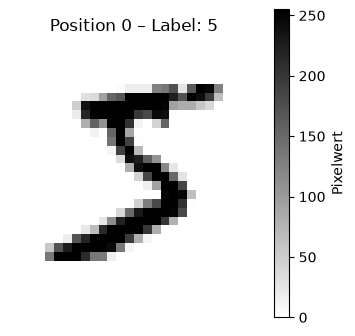

In [4]:
plt.figure(figsize=(4, 4))
plt.imshow(x_train_original[0], cmap="gray_r")
plt.title(f"Position 0 – Label: {y_train_original[0]}")
plt.colorbar(label="Pixelwert")
plt.axis("off")
plt.show()

Das erste Bild stellt tatsächlich die Ziffer **5** dar; das zugehörige Label `y_train_original[0]` ist ebenfalls 5.

## 1.4 Warum braucht der Output-Layer 10 Knoten?

MNIST enthält zehn mögliche Klassen, nämlich die Ziffern **0 bis 9**. Für jede Klasse wird ein Ausgabeknoten benötigt. Die Softmax-Aktivierung erzeugt für diese zehn Knoten Wahrscheinlichkeiten, deren Summe 1 ergibt. Die Klasse mit der höchsten Wahrscheinlichkeit ist die Vorhersage des Modells.

## Daten für das Modell vorbereiten

Die Bilder werden zu Vektoren mit 784 Werten umgeformt und auf den Bereich 0 bis 1 normalisiert. Die ganzzahligen Labels werden one-hot-kodiert.

In [5]:
x_train = x_train_original.reshape(-1, 784).astype("float32") / 255.0
x_test = x_test_original.reshape(-1, 784).astype("float32") / 255.0

y_train = to_categorical(y_train_original, num_classes=10)
y_test = to_categorical(y_test_original, num_classes=10)

print("x_train:", x_train.shape)
print("x_test: ", x_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)
print("Erstes Label vor One-hot:", y_train_original[0])
print("Erstes Label nach One-hot:", y_train[0])

x_train: (60000, 784)
x_test:  (10000, 784)
y_train: (60000, 10)
y_test:  (10000, 10)
Erstes Label vor One-hot: 5
Erstes Label nach One-hot: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## 1.5 Modell implementieren und kompilieren

In [6]:
model = Sequential([
    Input(shape=(784,)),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax"),
])

model.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Das Modell besitzt 50.890 trainierbare Parameter: 784×64 + 64 im Hidden-Layer und 64×10 + 10 im Output-Layer.

## 1.6 Modell trainieren

In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    verbose=1,
)

Epoch 1/5


  1/469 ━━━━━━━━━━━━━━━━━━━━ 2:46 356ms/step - accuracy: 0.1562 - loss: 2.4477

 37/469 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6860 - loss: 1.2026    

 74/469 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7785 - loss: 0.8852

112/469 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8147 - loss: 0.7284

147/469 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8363 - loss: 0.6372

... (60 outputs left out)

379/469 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9706 - loss: 0.1013

421/469 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9705 - loss: 0.1007

464/469 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9709 - loss: 0.1002

469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9709 - loss: 0.1001


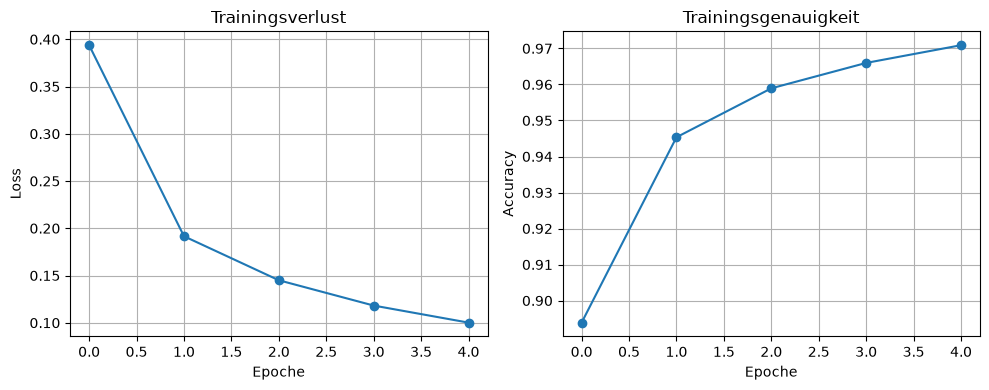

In [8]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], marker="o")
plt.title("Trainingsverlust")
plt.xlabel("Epoche")
plt.ylabel("Loss")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], marker="o")
plt.title("Trainingsgenauigkeit")
plt.xlabel("Epoche")
plt.ylabel("Accuracy")
plt.grid(True)

plt.tight_layout()
plt.show()

## 1.7 Modell mit den Testdaten evaluieren

In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=1)
print(f"Test-Loss: {test_loss:.4f}")
print(f"Test-Accuracy: {test_accuracy:.4f} ({test_accuracy:.2%})")

  1/313 ━━━━━━━━━━━━━━━━━━━━ 30s 97ms/step - accuracy: 1.0000 - loss: 0.0469

 57/313 ━━━━━━━━━━━━━━━━━━━━ 0s 894us/step - accuracy: 0.9605 - loss: 0.1337

111/313 ━━━━━━━━━━━━━━━━━━━━ 0s 913us/step - accuracy: 0.9595 - loss: 0.1303

165/313 ━━━━━━━━━━━━━━━━━━━━ 0s 921us/step - accuracy: 0.9587 - loss: 0.1328

216/313 ━━━━━━━━━━━━━━━━━━━━ 0s 937us/step - accuracy: 0.9624 - loss: 0.1232

269/313 ━━━━━━━━━━━━━━━━━━━━ 0s 940us/step - accuracy: 0.9667 - loss: 0.1085

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9678 - loss: 0.1042  

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9678 - loss: 0.1042


Test-Loss: 0.1042
Test-Accuracy: 0.9678 (96.78%)


Wahrscheinlichkeiten: [0.000e+00 0.000e+00 0.000e+00 7.000e-04 0.000e+00 0.000e+00 0.000e+00
 9.993e-01 0.000e+00 0.000e+00]
Vorhergesagte Ziffer: 7
Tatsächliche Ziffer: 7


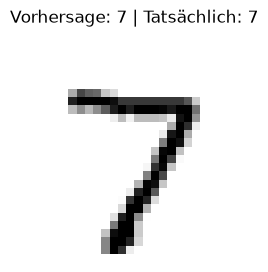

In [10]:
y_pred = model.predict(x_test[:1], verbose=0)
predicted_digit = int(np.argmax(y_pred[0]))

print("Wahrscheinlichkeiten:", np.round(y_pred[0], 4))
print("Vorhergesagte Ziffer:", predicted_digit)
print("Tatsächliche Ziffer:", int(y_test_original[0]))

plt.figure(figsize=(3, 3))
plt.imshow(x_test_original[0], cmap="gray_r")
plt.title(f"Vorhersage: {predicted_digit} | Tatsächlich: {y_test_original[0]}")
plt.axis("off")
plt.show()

## Fazit

Das neuronale Netz kann die handgeschriebenen Ziffern des MNIST-Testdatensatzes mit hoher Genauigkeit klassifizieren. Durch das Umformen auf 784 Eingabewerte kann jedes Bild von Dense-Layern verarbeitet werden; die zehn Softmax-Ausgänge repräsentieren die Ziffern 0 bis 9.